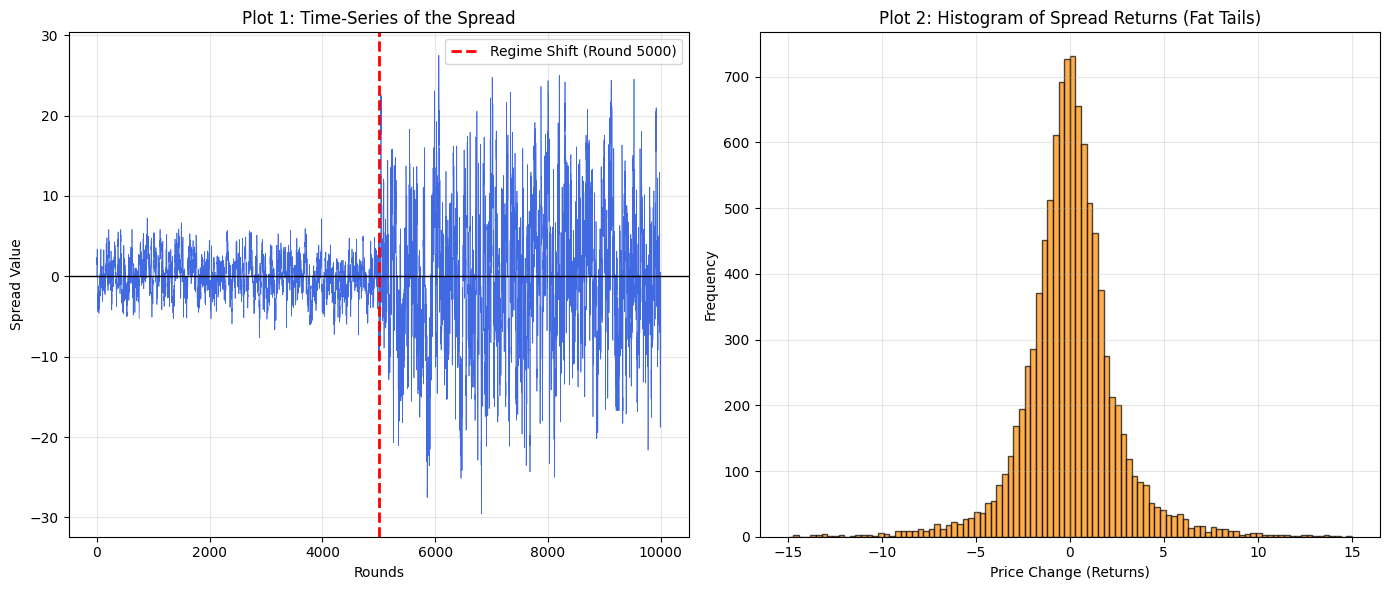

In [1]:
import numpy as np
import matplotlib.pyplot as plt

# Set random seed for reproducibility
np.random.seed(42)

# ==========================================
# 1. GENERATE DATA FOR PLOT 1: TIME-SERIES
# ==========================================
rounds = 10000
half = rounds // 2

# Mean-reverting parameters (Ornstein-Uhlenbeck process)
theta = 0.1  # Speed of mean reversion
mu = 0.0     # Mean center

# Regime 1: Low Volatility (Rounds 1 to 5,000)
sigma_1 = 1.0 
spread_1 = np.zeros(half)
for t in range(1, half):
    spread_1[t] = spread_1[t-1] + theta * (mu - spread_1[t-1]) + np.random.normal(0, sigma_1)

# Regime 2: High Volatility (Rounds 5,001 to 10,000)
sigma_2 = 4.0 
spread_2 = np.zeros(half)
# Start where the first half left off
spread_2[0] = spread_1[-1] 
for t in range(1, half):
    spread_2[t] = spread_2[t-1] + theta * (mu - spread_2[t-1]) + np.random.normal(0, sigma_2)

# Combine both regimes
full_spread = np.concatenate([spread_1, spread_2])

# ==========================================
# 2. GENERATE DATA FOR PLOT 2: FAT-TAILED HISTOGRAM
# ==========================================
# We use a Student's t-distribution with low degrees of freedom (df=2.5) 
# to create a sharp peak at 0 and long, heavy "fat-tail" wings out to the sides
fat_tail_returns = np.random.standard_t(df=2.5, size=10000)
# Scale it down slightly so the bulk sits near zero
fat_tail_returns = fat_tail_returns * 1.5

# ==========================================
# 3. PLOTTING
# ==========================================
plt.figure(figsize=(14, 6))

# Plot 1: Time-Series of the Spread
plt.subplot(1, 2, 1)
plt.plot(full_spread, color='royalblue', lw=0.5)
plt.axvline(x=half, color='red', linestyle='--', lw=2, label='Regime Shift (Round 5000)')
plt.axhline(y=0, color='black', linestyle='-', lw=1)
plt.title("Plot 1: Time-Series of the Spread")
plt.xlabel("Rounds")
plt.ylabel("Spread Value")
plt.legend()
plt.grid(alpha=0.3)

# Plot 2: Histogram of Spread Returns
plt.subplot(1, 2, 2)
# Clip extreme values just for clean histogram viewing, but keep the wings visible
plt.hist(fat_tail_returns, bins=100, range=(-15, 15), color='darkorange', edgecolor='black', alpha=0.7)
plt.title("Plot 2: Histogram of Spread Returns (Fat Tails)")
plt.xlabel("Price Change (Returns)")
plt.ylabel("Frequency")
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

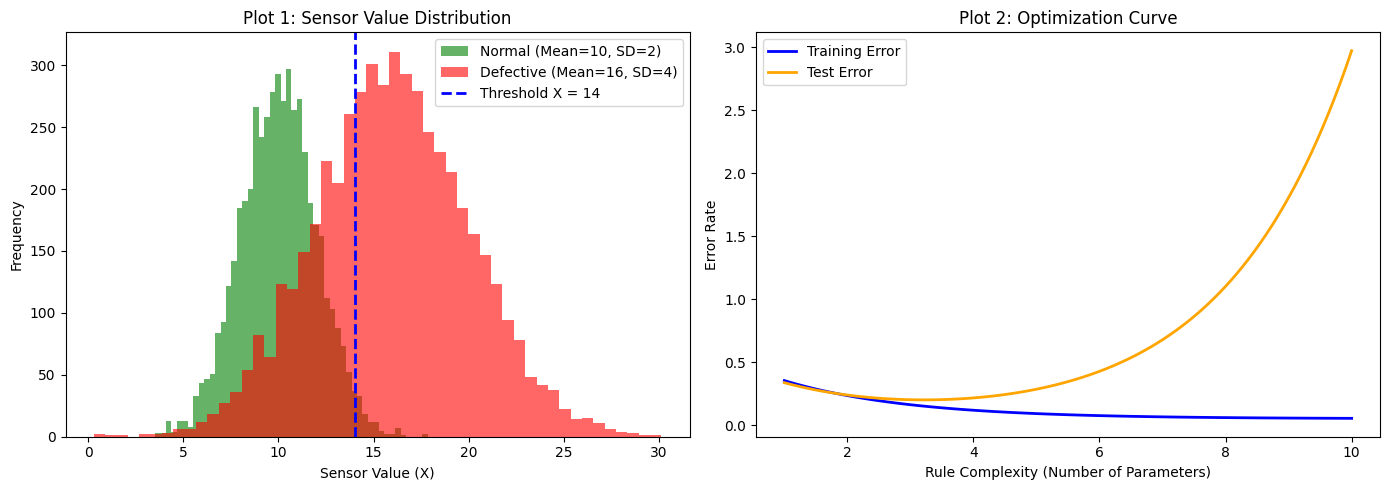

In [2]:
import numpy as np
import matplotlib.pyplot as plt
import scipy.stats as stats

np.random.seed(42)

# Plot 1 Data
normal_data = np.random.normal(10, 2, 5000)
defective_data = np.random.normal(16, 4, 5000)

# Plot 2 Data
complexity = np.linspace(1, 10, 100)
train_error = 0.5 * np.exp(-0.5 * complexity) + 0.05
test_error = 0.5 * np.exp(-0.5 * complexity) + 0.02 * np.exp(0.5 * complexity)

plt.figure(figsize=(14, 5))

# Subplot 1
plt.subplot(1, 2, 1)
plt.hist(normal_data, bins=50, alpha=0.6, label='Normal (Mean=10, SD=2)', color='g')
plt.hist(defective_data, bins=50, alpha=0.6, label='Defective (Mean=16, SD=4)', color='r')
plt.axvline(x=14, color='blue', linestyle='--', lw=2, label='Threshold X = 14')
plt.title("Plot 1: Sensor Value Distribution")
plt.xlabel("Sensor Value (X)")
plt.ylabel("Frequency")
plt.legend()

# Subplot 2
plt.subplot(1, 2, 2)
plt.plot(complexity, train_error, label='Training Error', color='blue', lw=2)
plt.plot(complexity, test_error, label='Test Error', color='orange', lw=2)
plt.title("Plot 2: Optimization Curve")
plt.xlabel("Rule Complexity (Number of Parameters)")
plt.ylabel("Error Rate")
plt.legend()

plt.tight_layout()
plt.show()

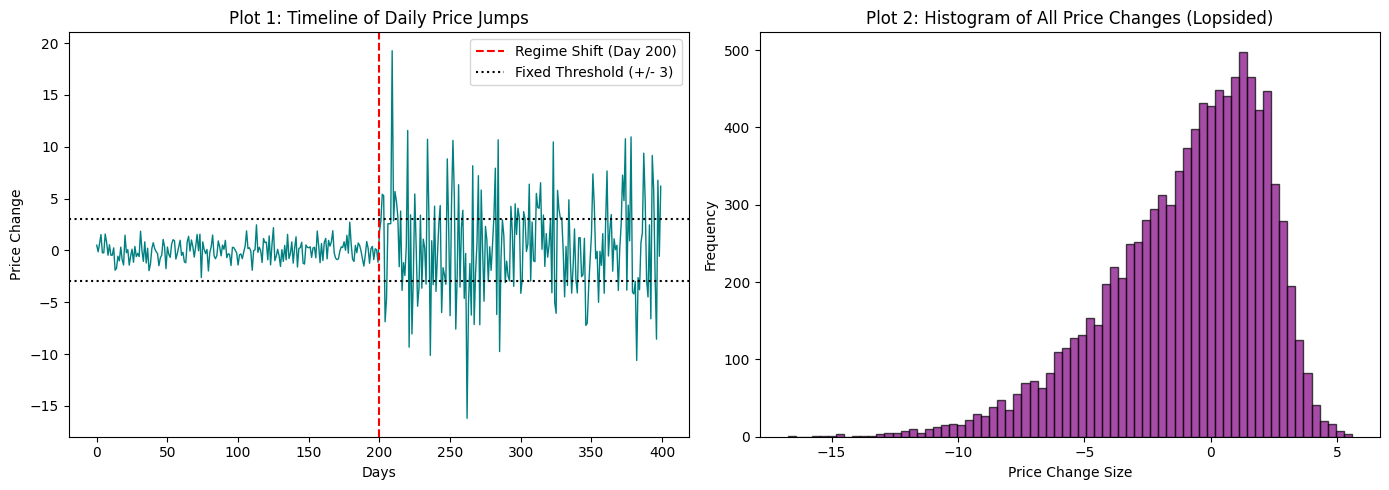

In [3]:
import numpy as np
import matplotlib.pyplot as plt
import scipy.stats as stats

# Set seed for consistency
np.random.seed(42)

# 1. Generate Data for Plot 1 (Variance Shift)
quiet_days = np.random.normal(0, 1, 200)
wild_days = np.random.normal(0, 5, 200)
timeline_data = np.concatenate([quiet_days, wild_days])

# 2. Generate Data for Plot 2 (Lopsided/Skewed Distribution)
# We use a negative skew to simulate steady small gains vs sudden big drops
skewed_data = stats.skewnorm.rvs(-6, loc=3, scale=5, size=10000)

# 3. Plotting
plt.figure(figsize=(14, 5))

# Subplot 1: Timeline
plt.subplot(1, 2, 1)
plt.plot(timeline_data, color='teal', lw=1)
plt.axvline(x=200, color='red', linestyle='--', label='Regime Shift (Day 200)')
plt.axhline(y=3, color='black', linestyle=':', label='Fixed Threshold (+/- 3)')
plt.axhline(y=-3, color='black', linestyle=':')
plt.title("Plot 1: Timeline of Daily Price Jumps")
plt.xlabel("Days")
plt.ylabel("Price Change")
plt.legend()

# Subplot 2: Lopsided Histogram
plt.subplot(1, 2, 2)
plt.hist(skewed_data, bins=70, color='purple', edgecolor='black', alpha=0.7)
plt.title("Plot 2: Histogram of All Price Changes (Lopsided)")
plt.xlabel("Price Change Size")
plt.ylabel("Frequency")

plt.tight_layout()
plt.show()

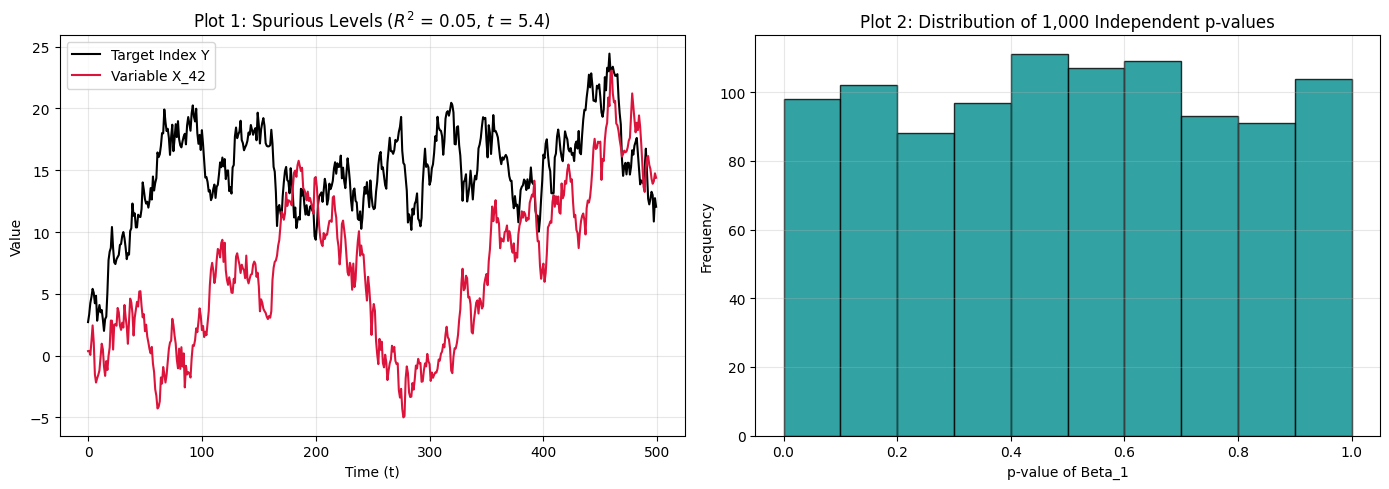

In [6]:
import numpy as np
import matplotlib.pyplot as plt
import scipy.stats as stats

# Set seed for reproducibility
np.random.seed(101)
n_samples = 500
n_variables = 1000

# ==========================================
# 1. PLOT 1 DATA: SPURIOUS REGRESSION (LEVELS)
# ==========================================
# Cumulative sums create non-stationary random walks
Y = np.cumsum(np.random.normal(0, 1, n_samples))
X_42 = np.cumsum(np.random.normal(0, 1, n_samples))

# Manual OLS Calculation for X_42 vs Y
x_mean, y_mean = np.mean(X_42), np.mean(Y)
ss_x = np.sum((X_42 - x_mean)**2)
ss_xy = np.sum((X_42 - x_mean) * (Y - y_mean))

beta_1 = ss_xy / ss_x
beta_0 = y_mean - beta_1 * x_mean

y_pred = beta_0 + beta_1 * X_42
residuals = Y - y_pred
rss = np.sum(residuals**2)
tss = np.sum((Y - y_mean)**2)

r_squared = 1 - (rss / tss)
sigma_sq = rss / (n_samples - 2)
se_beta_1 = np.sqrt(sigma_sq / ss_x)
t_stat = beta_1 / se_beta_1

# ==========================================
# 2. PLOT 2 DATA: MULTIPLE TESTING (RETURNS)
# ==========================================
Y_returns = np.random.normal(0, 1, n_samples)
X_matrix = np.random.normal(0, 1, (n_samples, n_variables))

p_values = []
y_ret_mean = np.mean(Y_returns)

# Loop through each independent variable and calculate the regression p-value manually
for i in range(n_variables):
    X_i = X_matrix[:, i]
    xi_mean = np.mean(X_i)
    ss_xi = np.sum((X_i - xi_mean)**2)
    ss_xiy = np.sum((X_i - xi_mean) * (Y_returns - y_ret_mean))
    
    b1 = ss_xiy / ss_xi
    b0 = y_ret_mean - b1 * xi_mean
    
    res = Y_returns - (b0 + b1 * X_i)
    rss_i = np.sum(res**2)
    
    sig_sq = rss_i / (n_samples - 2)
    se_b1 = np.sqrt(sig_sq / ss_xi)
    t_val = b1 / se_b1
    
    # Two-tailed p-value from t-distribution survival function
    p_val = stats.t.sf(np.abs(t_val), df=n_samples - 2) * 2
    p_values.append(p_val)

# ==========================================
# 3. PLOTTING
# ==========================================
plt.figure(figsize=(14, 5))

# Subplot 1: Spurious Regression
plt.subplot(1, 2, 1)
plt.plot(Y, label='Target Index Y', color='black')
plt.plot(X_42, label='Variable X_42', color='crimson')
plt.title(f"Plot 1: Spurious Levels ($R^2$ = {r_squared:.2f}, $t$ = {t_stat:.1f})")
plt.xlabel("Time (t)")
plt.ylabel("Value")
plt.legend()
plt.grid(alpha=0.3)

# Subplot 2: Uniform p-values
plt.subplot(1, 2, 2)
plt.hist(p_values, bins=10, range=(0, 1), color='darkcyan', edgecolor='black', alpha=0.8)
plt.title("Plot 2: Distribution of 1,000 Independent p-values")
plt.xlabel("p-value of Beta_1")
plt.ylabel("Frequency")
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

In [ ]:
sdfa